# Fed-hike tail, the hedge: does Polymarket cover a short SR3 put? Coverage, tail pricing, forecasts

## S0 · Summary

| question | answer |
|---|---|
| When a short SR3 put paid out, did the owner's Polymarket hike hedge pay too, and are Polymarket's Fed tails fairly priced? | rendered below from the run |

In [1]:
from IPython.display import Markdown, display
S0_HANDLE = display(Markdown("_S0 is rendered by the last cell of S7 when the run finishes._"), display_id=True)

**Fed-hike tail, the hedge: does Polymarket cover a short SR3 put?** · **NOT SHOWN**

**Research question** When a short SR3 put paid out, did the owner's Polymarket 50+ bp hike hedge pay too, and are Polymarket's Fed tails fairly priced?

NOT SHOWN. The put paid in 1 of 10 quarters and the hedge could be bought in 1; it returned 0% of the loss. 17 hike tails won 0 against 0.21 expected. The test could not reject fair pricing, so mispricing is not shown.

**Implementation**

| | |
|:--|:--|
| Trade | Short 40 SR3 puts a quarter, held to expiry |
| Hedge A | 22,013 YES of 50+ bps increase, every meeting before expiry |
| Hedge B | The same YES on the first meeting after expiry, sold at expiry |
| Prices | Polymarket daily samples [API]; Treasury bill forward for SR3 [U] |
| Costs | half-spread 0.2c [U]; Polymarket fees as served [U] |
| Window | 2024-04-30 to 2026-09-16, 20,844 h, 2 regimes |

**The numbers that matter**

| At | Metric | Value | Bar | |
|:--|:--|--:|:--|:--|
| 1 qtr | Hedge A return on the put's loss | 0.0% | >= 50% over 3+ quarters | INFO |
| 60 d | P(0 wins \| priced right), hike tails | 0.81 | rejects fair if below 0.05 | FAIL |
| 60 d | Polymarket mean error, against no change | 7.7 bp | no change 9.4 bp | PASS |
| tails | Hike-tail return, 0.2c half-spread | -100.0% |  | INFO |

**Hedge on the put's loss**

| Metric | Value | Bar | |
|:--|--:|:--|:--|
| Quarters the put paid | 1 of 10 |  |  |
| Hedge A bought in those | 1 of 1 |  |  |
| Hedge A return on the loss | 0.0% | >= 50% over 3+ quarters | INFO |
| Hedge A cost a year | USD 74 |  |  |
| Hedge A net a year | USD -74 |  |  |
| Hedge B return on the loss | 3.5% |  |  |
| Hedge B net a year | USD -223 |  |  |

**Tails, 60 days out**

| Metric | Value | Bar | |
|:--|--:|:--|:--|
| Hike tails priced under 5c | 17 |  |  |
| Hike-tail wins expected | 0.21 |  |  |
| Hike-tail wins | 0 |  |  |
| Wins minus expected | -0.21 |  |  |
| P(0 wins \| priced right) | 0.81 | rejects fair if below 0.05 | FAIL |
| Cut tails: wins, expected | 0, 0.29 |  |  |

**Forecast, 16 meetings**

| Metric | Value | Bar | |
|:--|--:|:--|:--|
| Mean abs error, 60 days out | 7.7 bp | no change 9.4 bp | PASS |
| Mean abs error, 30 days out | 4.8 bp |  |  |
| Mean abs error, 7 days out | 2.7 bp |  |  |
| Mean abs error, 1 day out | 1.1 bp |  |  |
| Mean abs error, no change | 9.4 bp |  |  |

**Data and checks**

| Metric | Value | Bar | |
|:--|--:|:--|:--|
| Fed meetings resolved | 20 |  |  |
| Outcomes priced the day before | 100% |  | PASS |
| Put book checks passed | 10 of 10 |  |  |

**Size**

| Half-spread, information only | Hike-tail return | Verdict |
|:--|--:|:--|
| 0.0c | -100.0% | INFO |
| **0.2c** | **-100.0%** | **INFO** |
| 0.5c | -100.0% | INFO |

Next test: re-run on SR3 futures once they land (B-0212); the Kalshi run shares this loss quarter, so it is not a replication.  
Not shown: 1 hedgeable loss quarter exists; 3 are needed for a verdict.  
Evidence only: the put's payout rides on the Treasury bill forward, not SR3 [U]; one window, 2 phases, 1 move of 50 bp or more.


## S1 · Setup

### S1.1 · Parameters

In [2]:
# ---- parameters: owner-set, study-set or [U]; venue and CME numbers are S1.2 ----
STUDY_ID = "2026-09-27-xasset-sofr-hike-tail-hedge-polymarket"
KIND, DESK, RUN_ID = "market", "lab/research", "research-003"
TITLE = "Fed-hike tail, the hedge: does Polymarket cover a short SR3 put?"
QUESTION = "When a short SR3 put paid out, did the owner's Polymarket 50+ bp hike hedge pay too, and are Polymarket's Fed tails fairly priced?"
SEED = 7
EQUITY, LOTS, Z, KAPPA = 1_000_000.0, 40, 1.0, 1.0        # research-001's base book
SLIP_BP, SLIP_FUT_BP, MIN_PREM_BP = 0.25, 0.25, 0.5       # [U], as research-001
OWN_YES = 22013                                           # owner 2026-09-27: YES contracts per meeting in the trade as sent
OWN_OUTCOME = "50+ bps increase"                          # owner 2026-09-27: the contract the trade as sent buys
HALF_SPREAD = 0.002                                       # [U] Polymarket history is sampled prices, not bid / ask: the cost to cross
SPREADS = (0.0, 0.002, 0.005)                             # [U] the S4 sweep of HALF_SPREAD
HORIZONS = (60, 30, 7, 1)                                 # days before the decision
GATE_HORIZON = 60                                         # [U] the forecast gate reads the horizon a hedge is bought at
HIST_DAYS = 100                                           # daily price samples fetched before each resolution
MAX_AGE_D = 7                                             # [U] a price sample older than this on the day it is read is not a price
TAIL_PX = 0.05                                            # [U] a tail is priced under 5c
BINS = (0, 0.02, 0.05, 0.15, 0.5, 0.85, 0.95, 1.0001)     # calibration buckets
P_REJECT = 0.05                                           # [U] fair pricing is rejected when P(what happened | fair) is below this
MIN_LOSS_Q = 3                                            # [U] fewer hedgeable loss quarters than this and no hedge verdict is given
CURVE_FROM = "2023-06-01"
START = "2024-03-01"
GATE_COVER_PCT = 50.0                                     # [U] a hedge worth having returns at least half the put's loss

### S1.2 · Assumptions

| item | value | source |
|---|---|---|
| SR3 value of 1 bp | USD 25 per contract | CME SR3 contract specs, read 2026-09-27 [V] (no card yet: `venues/cme` is docs-only) |
| SR3 option strikes | every 6.25 bp near the money | CME SR3 option specs, read 2026-09-27 [V] |
| CME fees | USD 0.89 per option, USD 1.25 per futures contract | IBKR CME pass-through table, read 2026-09-27 [1] |
| the put book | research-001's rule: each quarter, 40 SR3 puts one realized-vol SD above the forward, held to expiry. Only its PAYOUT is used; its premium is not (no SR3 option history) | `fundplat.quant.tradfi.rates_options` over the Treasury par curve [V] |
| the carrier | the Treasury bill forward stands in for SR3 until SR3 futures land | [U] |
| hedge A, every meeting before expiry (the trade as sent) | 22,013 YES of the owner's contract for every meeting between the quarter's entry and the option's expiry, held to resolution; a meeting that did not list it is marked, never replaced by another outcome | owner's trade, made systematic |
| hedge B, meeting after expiry | the same YES on the FIRST meeting after the expiry, sold at expiry; the put settles on that meeting's priced move | [U] |
| prices | Polymarket's daily `prices-history` samples, rejected when older than the S1.1 limit; the half-spread is added to buy and taken off to sell | [API] + [U] |
| fees | each market's fee fields as served today, through `fundplat.quant.predmkts.match`; a market that serves none is charged 0 | [U] |
| realized decision | each event's winning outcome; "25+", "50+" and "75+" outcomes are read at their lower bound | Polymarket resolution [API] |

In [3]:
import datetime as dt, json, math, re, time, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from fundplat.data.tradfi import rates as RATES
from fundplat.data.predmkts import polymarket as PM
from fundplat.quant.predmkts import match as MATCH
from fundplat.quant.tradfi import rates_options as RO
from fundplat.quant.core import report as REPORT

warnings.filterwarnings("ignore", category=DeprecationWarning)
NOW = dt.datetime.now(dt.timezone.utc)
USD_PER_BP, STRIKE_STEP_BP, FEE_OPT, FEE_FUT = 25.0, 6.25, 0.89, 1.25     # the S1.2 table
INK, GRID, AXIS = "#1f2937", "#e5e7eb", "#9ca3af"
C_BOOK, C_HEDGE, C_COST, C_LOSS, C_ALT = "#1f6feb", "#16a34a", "#6b7280", "#dc2626", "#d97706"
plt.rcParams.update({"figure.dpi": 96, "axes.edgecolor": AXIS, "axes.grid": True, "grid.color": GRID, "axes.axisbelow": True,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
LEG = dict(frameon=False)
KFMT = FuncFormatter(lambda v, _: f"{v:,.0f}")
FIGURES = []


def ask(ax, q, sub):
    ax.set_title(q, loc="left", fontsize=11, fontweight="bold", color=INK, pad=18)
    ax.text(0, 1.012, sub, transform=ax.transAxes, fontsize=8, color=C_COST, va="bottom")


def fig(fid, section, title, kind):
    # kind = the chart type's slug in app/library/research/charts.md
    FIGURES.append({"id": fid, "section": section, "title": title, "kind": kind})


def mdt(df, fmt=None):
    fmt = fmt or {}
    cols = [str(c) for c in df.columns]
    out = ["| " + " | ".join([df.index.name or ""] + cols) + " |", "|" + "---|" * (len(cols) + 1)]
    for i, r in df.iterrows():
        out.append("| " + " | ".join([str(i)] + [("-" if (isinstance(v, float) and np.isnan(v)) else fmt.get(c, "{}").format(v))
                                                  for c, v in zip(df.columns, r)]) + " |")
    return "\n".join(out)


usd = lambda v: f"USD {v:,.0f}"
pl = lambda n, one, many=None: f"{n} {one if n == 1 else (many or one + 's')}"   # a count with its noun, singular for 1
PROSE = {"USD 25 per bp": (USD_PER_BP, 25.0), "strikes 6.25 bp": (STRIKE_STEP_BP, 6.25), "option fee 0.89": (FEE_OPT, 0.89),
         "futures fee 1.25": (FEE_FUT, 1.25), "40 puts": (LOTS, 40), "22,013 YES": (OWN_YES, 22013)}
BAD = {k_: v_ for k_, v_ in PROSE.items() if v_[0] != v_[1]}
assert not BAD, f"the S1 tables no longer describe this run: {BAD}"
print(f"S1 tables: {len(PROSE)} stated numbers equal the code · run {NOW:%Y-%m-%d %H:%MZ}")

S1 tables: 6 stated numbers equal the code · run 2026-10-05 11:58Z


### S1.3 · Data

Every input below is REQUESTED through the data door (`fundplat.data`, whose door for agents is the `market` MCP: `md_rates`,
`md_predmkt_history`): a cold cache simply pulls it, and what the kernel read through the store is pinned in the manifest cell (`inputs`).

| source | what | the MCP's tool | guard |
|---|---|---|---|
| `fundplat.data.tradfi.rates` | the Treasury par curve (the carrier) | `md_rates` (TREASURY_PAR) | not stale |
| `fundplat.data.predmkts.polymarket` | every resolved "Fed decision in ...?" / "Fed Interest Rates: ..." event (tag `fed-rates`), each outcome's daily price before its resolution | `md_predmkt_history` | one winner per event; every outcome priced |

**Venue limits that bite here.** Polymarket serves one daily SAMPLED price per outcome token (not a bid and ask), so a thin
market can have a hole: a sample older than `MAX_AGE_D` days on the day it is read is rejected, never carried. The fund does
not store prediction-market history (predmkts is not served by `handle.pull` yet, B-0325), so Polymarket's events and price
samples are re-pulled at every run and named in `inputs.unpinned`; only the Treasury curve is pinned.

In [4]:
# ---- PULLS (cold cache = a pull, not an error): Treasury par curve CURVE_FROM -> newest row; every resolved Polymarket Fed-decision event
# ---- (tag fed-rates) and, per outcome, HIST_DAYS daily samples before its resolution ----
print(f"pulling through fundplat.data: Treasury par curve {CURVE_FROM} -> newest · Polymarket fed-rates events, resolved, "
      f"{HIST_DAYS} daily samples before each resolution (not stored, so re-pulled every run)")
TEN = {"1M": 1 / 12, "2M": 2 / 12, "3M": 0.25, "4M": 4 / 12, "6M": 0.5, "1Y": 1.0}
rows, CMETA = RATES.par_yield_curve(CURVE_FROM, None, with_meta=True)
assert not CMETA["stale"], "Treasury served from a stale cache"
CUR = pd.DataFrame([{"date": r["date"], **{k: r["tenors"].get(k) for k in TEN}} for r in rows])
CUR["date"] = pd.to_datetime(CUR["date"])
CUR = CUR.set_index("date").sort_index().apply(pd.to_numeric).dropna(subset=["3M", "6M"])
DATES = CUR.index
CT = {d: (np.array([TEN[k] for k in TEN if pd.notna(r[k])]), np.array([r[k] for k in TEN if pd.notna(r[k])])) for d, r in CUR.iterrows()}
CM36 = pd.Series([RO.fwd_bp(*CT[d], 0.25, 0.5) for d in DATES], index=DATES)
RV63 = CM36.diff().rolling(63).std() * math.sqrt(252)


def value(o):
    # the move an outcome names, bp: +/-25, +/-50, +/-75 ("N+" read at N), 0 for no change; None for "Other"
    o = str(o).lower()
    if "no change" in o:
        return 0
    m = re.search(r"(\d+)\+?\s*bps", o)
    if not m:
        return None
    return int(m.group(1)) * (1 if "increase" in o else -1 if "decrease" in o else 0) or None


BAR_MIN = 1440                                            # one daily price sample per read (the profile's bar)
EVP = [e for e in PM.closed_events(tag_slug="fed-rates", max_pages=50)
       if (e.get("title") or "").lower().startswith(("fed decision in", "fed interest rates:"))]
OUT, HIST = [], {}
for e in EVP:
    for mk in e.get("markets") or []:
        r = PM.parse_market(mk, e)
        if not r.get("token_ids") or not r.get("close_ts") or not r.get("outcome_prices"):
            continue
        tok = r["token_ids"][0]
        h = PM.history(tok, days=HIST_DAYS, fidelity=BAR_MIN, end_s=int(r["close_ts"] // 1000))
        HIST[tok] = pd.Series({x["t"]: x["p"] for x in h}, dtype=float).sort_index()
        OUT.append({"event": e["slug"], "outcome": r["group_item_title"], "v": value(r["group_item_title"]), "token": tok,
                    "won": float(r["outcome_prices"][0]) == 1.0, "close": pd.Timestamp(r["close_ts"], unit="ms"),
                    "fee_rate": r.get("fee_rate"), "fee_exp": r.get("fee_exponent"), "fees_on": r.get("fees_enabled")})
OUT = pd.DataFrame(OUT)
DEC = OUT.groupby("event").close.max().rename("decision").to_frame()
OUT = OUT.join(DEC, on="event")
STALE = {"read": 0, "stale": 0}


def price(tok, when):
    # the last daily sample at or before `when`, if no older than MAX_AGE_D
    s = HIST[tok]
    s = s[s.index <= int(when.timestamp() * 1000)]
    if not len(s):
        return np.nan
    STALE["read"] += 1
    if (when - pd.Timestamp(s.index[-1], unit="ms")).days > MAX_AGE_D:
        STALE["stale"] += 1
        return np.nan
    return float(s.iloc[-1])


def fee(row, px):
    # today's fee fields; a market that serves none is charged 0 [U]
    rate = None if pd.isna(row.fee_rate) else row.fee_rate
    f = MATCH.pm_taker_fee(px, rate, None if pd.isna(row.fee_exp) else row.fee_exp, bool(row.fees_on) if pd.notna(row.fees_on) else False,
                           contracts=1.0)
    return 0.0 if f is None or not np.isfinite(f) else float(f)


for h in HORIZONS:
    OUT[f"p{h}"] = [price(t, d - pd.Timedelta(days=h)) for t, d in zip(OUT.token, OUT.decision)]
WON = OUT[OUT.won].set_index("event")
REAL = DEC.join(WON.v.rename("move")).sort_values("decision")
MV = REAL.move.dropna()
SIGNS = np.sign(MV[MV != 0])
N_REGIMES = int((SIGNS != SIGNS.shift()).sum())
N_BIG = int((MV.abs() >= 50).sum())
FEES_ON = OUT.assign(y=OUT.decision.dt.year, on=OUT.fees_on.fillna(False).astype(bool)).groupby("y").on.mean() * 100
WINDOW = {"from": f"{DEC.decision.min():%Y-%m-%dT%H:%MZ}", "to": f"{DEC.decision.max():%Y-%m-%dT%H:%MZ}",
          "hours": int((DEC.decision.max() - DEC.decision.min()).total_seconds() // 3600), "regimes": N_REGIMES}
WS = f"{WINDOW['from'][:10]} -> {WINDOW['to'][:10]}, {len(DEC)} meetings"
print(f"Polymarket {len(EVP)} resolved Fed events, {len(OUT)} outcomes, {WS} [API]; {N_REGIMES} hiking / cutting phases, {pl(N_BIG, 'move')} of "
      f"50 bp or more; fees served on: " + ", ".join(f"{y} {v:.0f}%" for y, v in FEES_ON.items()) +
      f". Treasury par curve {DATES[0]:%Y-%m-%d} -> {DATES[-1]:%Y-%m-%d} [V]")

pulling through fundplat.data: Treasury par curve 2023-06-01 -> newest · Polymarket fed-rates events, resolved, 100 daily samples before each resolution (not stored, so re-pulled every run)


Polymarket 20 resolved Fed events, 88 outcomes, 2024-04-30 -> 2026-09-16, 20 meetings [API]; 2 hiking / cutting phases, 1 move of 50 bp or more; fees served on: 2024 0%, 2025 0%, 2026 70%. Treasury par curve 2023-06-01 -> 2026-10-02 [V]


### S1.4 · Runs

The put book is research-001's engine run over this window; its `verify()` passes before anything is drawn.

In [5]:
RES = RO.sell_and_hold(RO.Curve({d.date(): v for d, v in CT.items()}), {d.date(): v for d, v in RV63.dropna().items()},
                       z=Z, kappa=KAPPA, usd_per_bp=USD_PER_BP, strike_step_bp=STRIKE_STEP_BP, fee_option=FEE_OPT,
                       fee_futures=FEE_FUT, slip_bp=SLIP_BP, slip_fut_bp=SLIP_FUT_BP, min_prem_bp=MIN_PREM_BP, start=dt.date.fromisoformat(START))
VER = RO.verify(RES)
assert all(bool(v[0]) for v in VER.values()), [k for k, v in VER.items() if not v[0]]
BOOK = pd.DataFrame(RES["quarters"])
for c in ("t0", "T", "expiry"):
    BOOK[c] = pd.to_datetime(BOOK[c])
BOOK = BOOK[BOOK.traded & (BOOK.t0 >= DEC.decision.min() - pd.Timedelta(days=91))].reset_index(drop=True)
BOOK["put payout USD"] = BOOK.pay * USD_PER_BP * LOTS
VERIFY = {"suite": "rates_options.verify", "passed": sum(bool(v[0]) for v in VER.values()), "total": len(VER), "books": 1}
print(f"put book: {len(BOOK)} quarters, {BOOK.t0.min():%Y-%m-%d} -> {BOOK['T'].max():%Y-%m-%d}; verify {VERIFY['passed']}/{VERIFY['total']}; "
      f"it paid in {pl(int((BOOK.pay > 0).sum()), 'quarter')}")

put book: 10 quarters, 2024-03-15 -> 2026-09-11; verify 10/10; it paid in 1 quarter


## S2 · Data checks

| question | gate to S3 |
|---|---|
| Does every event resolve to exactly one outcome, is every outcome priced, and what did the Fed do? | one winner per event; every outcome priced on the day before |

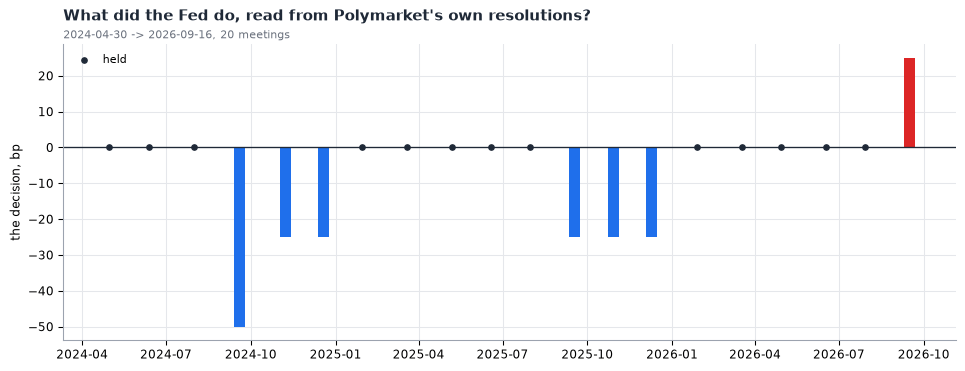

| year | events | outcomes | priced 60 days out % | events listing the owner's contract |
|---|---|---|---|---|
| 2024 | 6 | 28 | 39 | 0 |
| 2025 | 8 | 33 | 100 | 0 |
| 2026 | 6 | 27 | 89 | 3 |

one winner per event: True; outcomes priced the day before: 100%; samples older than 7 days rejected: 4 of 331 reads


In [6]:
ONE_WIN = bool((OUT.groupby("event").won.sum() == 1).all())
PRICED = float(OUT.p1.notna().mean() * 100)
LISTED = OUT.groupby("event").outcome.apply(lambda s: OWN_OUTCOME in set(s)).rename("lists the owner's contract")
QCOV = OUT.assign(year=OUT.decision.dt.year, g=OUT[f"p{GATE_HORIZON}"].notna()).groupby("year").agg(
    events=("event", "nunique"), outcomes=("token", "size"), priced=("g", "mean"))
QCOV["priced"] *= 100
QCOV["events listing the owner's contract"] = LISTED.groupby(DEC.decision.dt.year.reindex(LISTED.index)).sum().reindex(QCOV.index).fillna(0)
QCOV.columns = ["events", "outcomes", f"priced {GATE_HORIZON} days out %", "events listing the owner's contract"]
QCOV.index.name = "year"
fig_, ax = plt.subplots(figsize=(12, 4))
ax.bar(REAL.decision, REAL.move, width=12, color=np.where(REAL.move > 0, C_LOSS, np.where(REAL.move < 0, C_BOOK, AXIS)))
ax.scatter(REAL.decision[REAL.move == 0], REAL.move[REAL.move == 0], color=INK, s=16, zorder=4, label="held")
ax.axhline(0, color=INK, lw=1); ax.legend(loc="upper left", fontsize=8, **LEG)
ax.set_ylabel("the decision, bp")
ask(ax, "What did the Fed do, read from Polymarket's own resolutions?", WS)
plt.show()
fig("fig:s2-decisions", "S2", "What did the Fed do, read from Polymarket's own resolutions?", "series-and-distribution")
display(Markdown(mdt(QCOV, {c: "{:.0f}" for c in QCOV.columns})))
print(f"one winner per event: {ONE_WIN}; outcomes priced the day before: {PRICED:.0f}%; samples older than {MAX_AGE_D} days rejected: "
      f"{STALE['stale']} of {STALE['read']} reads")

## S3 · Core result

| question | gate to S4 |
|---|---|
| In the quarters the short put paid, did the owner's contract pay, and what did it cost the rest of the time? | over the loss quarters where hedge A could be bought, it returned at least the S1.1 share of the put's loss; fewer such quarters than the S1.1 minimum and no verdict is given |

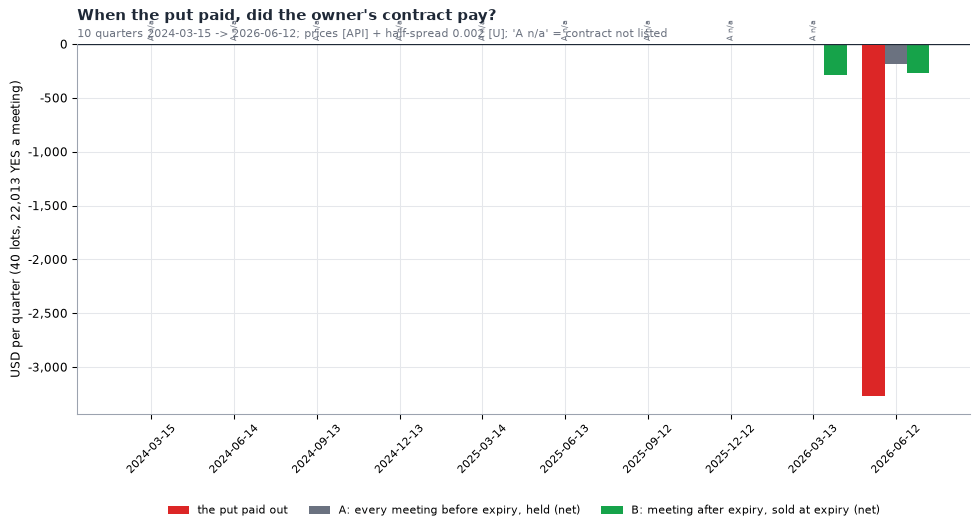

| quarter | put payout USD | A | A entry delay, days | A cost USD | A paid USD | B | B cost USD | B sold for USD |
|---|---|---|---|---|---|---|---|---|
| 2024-03-15 | 0 | not listed (2) | - | 0 | 0 | not listed | 0 | 0 |
| 2024-06-14 | 0 | not listed (1) | - | 0 | 0 | not listed | 0 | 0 |
| 2024-09-13 | 0 | not listed (2) | - | 0 | 0 | not listed | 0 | 0 |
| 2024-12-13 | 0 | not listed (2) | - | 0 | 0 | not listed | 0 | 0 |
| 2025-03-14 | 0 | not listed (2) | - | 0 | 0 | not listed | 0 | 0 |
| 2025-06-13 | 0 | not listed (2) | - | 0 | 0 | not listed | 0 | 0 |
| 2025-09-12 | 0 | not listed (3) | - | 0 | 0 | not listed | 0 | 0 |
| 2025-12-12 | 0 | not listed (1) | - | 0 | 0 | not listed | 0 | 0 |
| 2026-03-13 | 0 | not listed (2) | - | 0 | 0 | bought | 289 | 0 |
| 2026-06-12 | 3,269 | 2 meetings | 0 | 185 | 0 | bought | 381 | 115 |

pm_hedge_coverage_pct=0.0 pm_hedge_cost_usd_yr=74 (the put paid in 1 of 10 quarters; the owner's contract could be bought in 1 of them; USD 185 per quarter it was bought)


In [7]:
def own(ev):
    o = OUT[(OUT.event == ev) & (OUT.outcome == OWN_OUTCOME)]
    return o.iloc[0] if len(o) else None


def first_price(tok, t0, until):
    s = HIST[tok]
    s = s[(s.index >= int(t0.timestamp() * 1000)) & (s.index <= int(until.timestamp() * 1000))]
    return (pd.Timestamp(s.index[0], unit="ms"), float(s.iloc[0])) if len(s) else (None, np.nan)


H = []
for _, q in BOOK.iterrows():
    meets = DEC[(DEC.decision > q.t0) & (DEC.decision <= q.expiry)].index
    nxt = DEC[DEC.decision > q.expiry].sort_values("decision").index
    a_cost = a_pay = 0.0
    bought = unlisted = 0
    delays = []
    for ev in meets:
        r = own(ev)
        if r is None:
            unlisted += 1
            continue
        when, p = first_price(r.token, q.t0, DEC.loc[ev, "decision"])
        if not np.isfinite(p):
            continue
        px = min(p + HALF_SPREAD, 0.999)
        a_cost += OWN_YES * (px + fee(r, px))
        a_pay += OWN_YES * float(r.won)
        bought += 1
        delays.append((when - q.t0).days)
    status_a = f"{bought} meetings" if bought else (f"not listed ({unlisted})" if unlisted else "no meeting")
    b_cost = b_sold = 0.0
    status_b = "not listed"
    if len(nxt) and own(nxt[0]) is not None:
        r = own(nxt[0])
        when, p = first_price(r.token, q.t0, q.expiry)
        if np.isfinite(p):
            px = min(p + HALF_SPREAD, 0.999)
            b_cost = OWN_YES * (px + fee(r, px))
            sp = price(r.token, q.expiry)
            sx = max(sp - HALF_SPREAD, 0.0) if np.isfinite(sp) else 0.0
            b_sold = OWN_YES * (sx - fee(r, sx)) if sx > 0 else 0.0
            status_b = "bought"
        else:
            status_b = "not priced"
    H.append({"quarter": f"{q.t0:%Y-%m-%d}", "put payout USD": q["put payout USD"], "A": status_a,
              "A entry delay, days": float(np.mean(delays)) if delays else np.nan, "A cost USD": a_cost, "A paid USD": a_pay,
              "B": status_b, "B cost USD": b_cost, "B sold for USD": b_sold})
H = pd.DataFrame(H).set_index("quarter")
H["A bought"] = H["A cost USD"] > 0
LOSSQ = H[H["put payout USD"] > 0]
LOSSQ_A = LOSSQ[LOSSQ["A bought"]]
PUT_LOSS, PUT_LOSS_A = LOSSQ["put payout USD"].sum(), LOSSQ_A["put payout USD"].sum()
COVER = LOSSQ_A["A paid USD"].sum() / PUT_LOSS_A * 100 if PUT_LOSS_A > 0 else np.nan            # gross: what the hedge returned
COVER_B = LOSSQ["B sold for USD"].sum() / PUT_LOSS * 100 if PUT_LOSS > 0 else np.nan
YRS_H = (pd.Timestamp(H.index[-1]) - pd.Timestamp(H.index[0])).days / 365.25 + 0.25
COST_YR = H["A cost USD"].sum() / YRS_H
COST_PER_HEDGED_Q = H.loc[H["A bought"], "A cost USD"].mean() if H["A bought"].any() else np.nan
NET_A_YR = (H["A paid USD"] - H["A cost USD"]).sum() / YRS_H
NET_B_YR = (H["B sold for USD"] - H["B cost USD"]).sum() / YRS_H
fig_, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(H))
ax.bar(x - 0.27, -H["put payout USD"], width=0.27, color=C_LOSS, label="the put paid out")
ax.bar(x, H["A paid USD"] - H["A cost USD"], width=0.27, color=C_COST, label="A: every meeting before expiry, held (net)")
ax.bar(x + 0.27, H["B sold for USD"] - H["B cost USD"], width=0.27, color=C_HEDGE, label="B: meeting after expiry, sold at expiry (net)")
for i_, b_ in enumerate(H["A bought"]):
    if not b_:
        ax.text(i_, 0, " A n/a", rotation=90, fontsize=6, color=C_COST, va="bottom", ha="center")
ax.set_xticks(x, H.index, rotation=45, fontsize=8); ax.axhline(0, color=INK, lw=1)
ax.yaxis.set_major_formatter(KFMT); ax.set_ylabel(f"USD per quarter ({LOTS} lots, {OWN_YES:,} YES a meeting)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=3, fontsize=8, **LEG)
ask(ax, "When the put paid, did the owner's contract pay?", f"{len(H)} quarters {H.index[0]} -> {H.index[-1]}; prices [API] + half-spread {HALF_SPREAD:.3f} [U]; 'A n/a' = contract not listed")
plt.show()
fig("fig:s3-coverage", "S3", "When the put paid, did the owner's contract pay?", "hedge-and-basis")
display(Markdown(mdt(H[["put payout USD", "A", "A entry delay, days", "A cost USD", "A paid USD", "B", "B cost USD", "B sold for USD"]],
                     {"put payout USD": "{:,.0f}", "A entry delay, days": "{:.0f}", "A cost USD": "{:,.0f}", "A paid USD": "{:,.0f}",
                      "B cost USD": "{:,.0f}", "B sold for USD": "{:,.0f}"})))
print(f"pm_hedge_coverage_pct={COVER:.1f} pm_hedge_cost_usd_yr={COST_YR:.0f} (the put paid in {len(LOSSQ)} of {len(H)} quarters; the owner's "
      f"contract could be bought in {len(LOSSQ_A)} of them; {usd(COST_PER_HEDGED_Q)} per quarter it was bought)")

## S4 · Robustness

| question | gate to S6 |
|---|---|
| Is the hike tail priced above what it paid? Would tails that paid nothing have paid nothing anyway if priced right? | fair pricing is rejected only when the chance of what happened, under the tails' own prices, is below the S1.1 level |

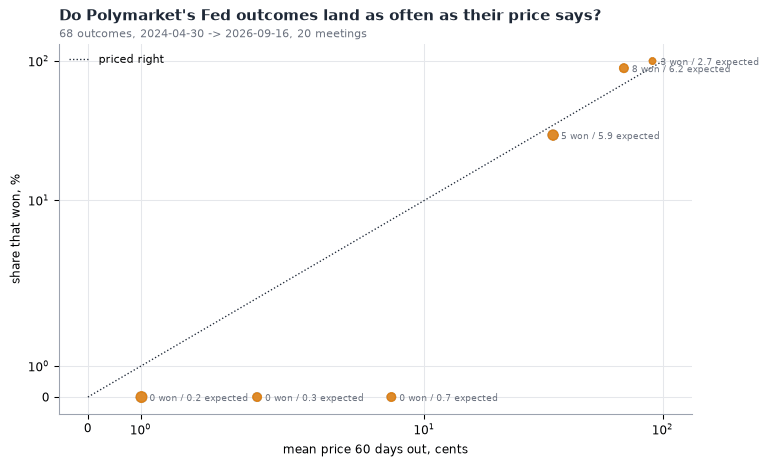

| price 60 days out | outcomes | events | mean price | wins expected at that price | wins |
|---|---|---|---|---|---|
| 0c to 2c | 21 | 15 | 0.010 | 0.2 | 0 |
| 2c to 5c | 9 | 7 | 0.032 | 0.3 | 0 |
| 5c to 15c | 9 | 8 | 0.073 | 0.7 | 0 |
| 15c to 50c | 17 | 13 | 0.346 | 5.9 | 5 |
| 50c to 85c | 9 | 9 | 0.687 | 6.2 | 8 |
| 85c to 95c | 3 | 3 | 0.905 | 2.7 | 3 |

| under 5c, 60 days out | outcomes | expected wins | wins | P(0 wins | priced right) |
|---|---|---|---|---|
| hike tails | 17 | 0.21 | 0 | 0.81 |
| cut tails | 12 | 0.29 | 0 | 0.74 |

| half-spread paid | hike-tail ROI % |
|---|---|
| 0.0 | -100.0 |
| 0.002 | -100.0 |
| 0.005 | -100.0 |

pm_tail_roi_pct=-100.0: 17 hike tails, 0 won against 0.21 expected; P(0 | priced right) 0.81


In [8]:
H0 = GATE_HORIZON
PC = OUT.dropna(subset=[f"p{H0}"]).copy()
PC["bucket"] = pd.cut(PC[f"p{H0}"], list(BINS), right=False)
CAL = PC.groupby("bucket", observed=True).agg(outcomes=("won", "size"), events=("event", "nunique"), mean_price=(f"p{H0}", "mean"),
                                              expected_wins=(f"p{H0}", "sum"), wins=("won", "sum"))
CAL.index = [f"{iv.left * 100:.0f}c to {min(iv.right, 1) * 100:.0f}c" for iv in CAL.index]
CAL.index.name = f"price {H0} days out"
CAL.columns = ["outcomes", "events", "mean price", "wins expected at that price", "wins"]


def tail_test(t):
    # expected wins, wins, P(0 wins | priced right) with one chance per event (a meeting's outcomes are exclusive)
    if not len(t):
        return 0.0, 0, np.nan
    per = t.groupby("event")[f"p{H0}"].sum().clip(upper=1)
    return float(t[f"p{H0}"].sum()), int(t.won.sum()), float(np.prod(1 - per.values))


TL = OUT[(OUT[f"p{H0}"] < TAIL_PX) & (OUT.v.fillna(0) > 0)].copy()      # the hike side, the side the hedge is on
TD = OUT[(OUT[f"p{H0}"] < TAIL_PX) & (OUT.v.fillna(0) < 0)].copy()      # the cut side, shown beside it
EXPECTED, WINS, P0 = tail_test(TL)
EXP_D, WINS_D, P0_D = tail_test(TD)
P_FAIR = P0 if WINS == 0 else np.nan


def tail_roi(t, hs):
    paid = [(p + hs) + fee(r, p + hs) for p, r in zip(t[f"p{H0}"], t.itertuples())]
    return (t.won.sum() - sum(paid)) / sum(paid) * 100 if len(t) else np.nan


ROI = {hs: tail_roi(TL, hs) for hs in SPREADS}
TAIL_ROI = ROI[HALF_SPREAD]
fig_, ax = plt.subplots(figsize=(8.5, 5))
g = PC.groupby("bucket", observed=True).agg(p=(f"p{H0}", "mean"), w=("won", "mean"), n=("won", "size"), e=(f"p{H0}", "sum"), k=("won", "sum"))
ax.scatter(g.p * 100, g.w * 100, s=np.sqrt(g.n) * 14, color=C_ALT, alpha=0.85)
for p_, w_, e_, k_ in zip(g.p, g.w, g.e, g.k):
    ax.annotate(f"{int(k_)} won / {e_:.1f} expected", (p_ * 100, w_ * 100), textcoords="offset points", xytext=(6, -3), fontsize=7, color=C_COST)
ax.plot([0, 100], [0, 100], color=INK, lw=1, ls=":", label="priced right")
ax.set_xscale("symlog", linthresh=5); ax.set_yscale("symlog", linthresh=5)
ax.set_xlabel(f"mean price {H0} days out, cents"); ax.set_ylabel("share that won, %"); ax.legend(loc="upper left", fontsize=8, **LEG)
ask(ax, "Do Polymarket's Fed outcomes land as often as their price says?", f"{len(PC)} outcomes, {WS}")
plt.show()
fig("fig:s4-calibration", "S4", "Do Polymarket's Fed outcomes land as often as their price says?", "calibration")
display(Markdown(mdt(CAL, {"outcomes": "{:.0f}", "events": "{:.0f}", "mean price": "{:.3f}", "wins expected at that price": "{:.1f}", "wins": "{:.0f}"})))
TT = pd.DataFrame({"hike tails": {"outcomes": len(TL), "expected wins": EXPECTED, "wins": WINS, "P(0 wins | priced right)": P0},
                   "cut tails": {"outcomes": len(TD), "expected wins": EXP_D, "wins": WINS_D, "P(0 wins | priced right)": P0_D}}).T
TT.index.name = f"under {TAIL_PX * 100:.0f}c, {H0} days out"
display(Markdown(mdt(TT, {"outcomes": "{:.0f}", "expected wins": "{:.2f}", "wins": "{:.0f}", "P(0 wins | priced right)": "{:.2f}"})))
display(Markdown(mdt(pd.DataFrame({"hike-tail ROI %": ROI}).rename_axis("half-spread paid"), {"hike-tail ROI %": "{:+.1f}"})))
print(f"pm_tail_roi_pct={TAIL_ROI:.1f}: {len(TL)} hike tails, {WINS} won against {EXPECTED:.2f} expected; P(0 | priced right) {P0:.2f}")

## S5 · Risk and diagnostics

| question | answer form |
|---|---|
| How close does Polymarket's expected decision come to what the Fed did, on the same meetings at every horizon? | error in bp against "no change"; the gate reads the S1.1 gate horizon |

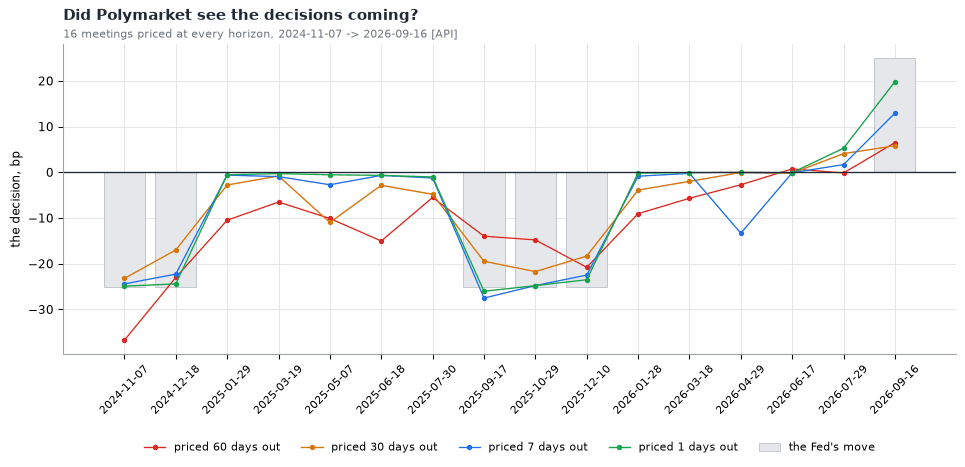

| forecast, on the same meetings | meetings | mean abs error bp | mean error bp |
|---|---|---|---|
| error 60d bp | 16 | 7.7 | -4.2 |
| error 30d bp | 16 | 4.8 | -1.1 |
| error 7d bp | 16 | 2.7 | -1.7 |
| error 1d bp | 16 | 1.1 | -0.1 |
| no-change error bp | 16 | 9.4 | +6.2 |

pm_mae_7d_bp=3.29 (all meetings priced 7 days out; on the common set 2.69)


In [9]:
F3 = []
for ev, g in OUT.groupby("event"):
    g = g[g.v.notna()]
    mv = REAL.loc[ev, "move"]
    if not np.isfinite(mv) or g.empty:
        continue
    row = {"meeting": f"{DEC.loc[ev, 'decision']:%Y-%m-%d}", "move bp": mv, "no-change error bp": -mv}
    for h in HORIZONS:
        p = g[f"p{h}"]
        ok = p.notna()
        row[f"error {h}d bp"] = float((p[ok] * g.v[ok]).sum() / p[ok].sum()) - mv if ok.any() and p[ok].sum() > 0 else np.nan
    F3.append(row)
F3 = pd.DataFrame(F3).set_index("meeting").sort_index()
COMMON = F3.dropna()
MAE = pd.DataFrame({c: {"meetings": len(COMMON), "mean abs error bp": COMMON[c].abs().mean(), "mean error bp": COMMON[c].mean()}
                    for c in [f"error {h}d bp" for h in HORIZONS] + ["no-change error bp"]}).T
MAE.index.name = "forecast, on the same meetings"
fig_, ax = plt.subplots(figsize=(12, 4.2))
xx = np.arange(len(COMMON))
ax.bar(xx, COMMON["move bp"], color=GRID, edgecolor=AXIS, lw=0.4, label="the Fed's move")
for h, c_ in zip(HORIZONS, (C_LOSS, C_ALT, C_BOOK, C_HEDGE)):
    ax.plot(xx, COMMON["move bp"] + COMMON[f"error {h}d bp"], color=c_, marker="o", ms=3, lw=1, label=f"priced {h} days out")
ax.set_xticks(xx, COMMON.index, rotation=45, fontsize=8); ax.axhline(0, color=INK, lw=1)
ax.set_ylabel("the decision, bp"); ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=5, fontsize=8, **LEG)
ask(ax, "Did Polymarket see the decisions coming?", f"{len(COMMON)} meetings priced at every horizon, {COMMON.index[0]} -> {COMMON.index[-1]} [API]")
plt.show()
fig("fig:s5-forecast", "S5", "Did Polymarket see the decisions coming?", "series-and-distribution")
display(Markdown(mdt(MAE, {"meetings": "{:.0f}", "mean abs error bp": "{:.1f}", "mean error bp": "{:+.1f}"})))
MAE_G = float(MAE.loc[f"error {GATE_HORIZON}d bp", "mean abs error bp"])
NC_MAE = float(MAE.loc["no-change error bp", "mean abs error bp"])
PM_MAE7 = float(F3["error 7d bp"].abs().mean())
print(f"pm_mae_7d_bp={PM_MAE7:.2f} (all meetings priced 7 days out; on the common set {MAE.loc['error 7d bp', 'mean abs error bp']:.2f})")

## S6 · Decision

| question | decision rule |
|---|---|
| What does this mean for the owner's hedge? | n/a - no position; implications only, rendered below |

In [10]:
IMPL = [f"The owner's contract could be bought in {len(LOSSQ_A)} of the {pl(len(LOSSQ), 'quarter')} the put paid, and returned {COVER:.0f}% of the put's loss "
        f"there; bought every quarter it was listed, it cost {usd(COST_PER_HEDGED_Q)} a quarter and ran {usd(NET_A_YR)} a year net.",
        f"Sold at expiry on the meeting after, it returned {COVER_B:.0f}% of the put's loss and ran {usd(NET_B_YR)} a year net.",
        "The mismatch is structural: the put settles on the forward rate for meetings AFTER its expiry; a contract on a meeting before it cannot see them.",
        f"The hike tails paid {WINS} times against {EXPECTED:.2f} expected at their prices; at this n that does not reject fair pricing.",
        "A CME put on the same contract caps every path; that is priced in research-001 Part A and untested here [U]."]
display(Markdown("\n".join(f"- {s}" for s in IMPL)))

- The owner's contract could be bought in 1 of the 1 quarter the put paid, and returned 0% of the put's loss there; bought every quarter it was listed, it cost USD 185 a quarter and ran USD -74 a year net.
- Sold at expiry on the meeting after, it returned 4% of the put's loss and ran USD -223 a year net.
- The mismatch is structural: the put settles on the forward rate for meetings AFTER its expiry; a contract on a meeting before it cannot see them.
- The hike tails paid 0 times against 0.21 expected at their prices; at this n that does not reject fair pricing.
- A CME put on the same contract caps every path; that is priced in research-001 Part A and untested here [U].

## S7 · Verdict

The gates, the conclusion and the manifest are rendered below from the run's own objects.

In [11]:
COLD = len(LOSSQ_A) < MIN_LOSS_Q
GATES = [
    {"id": "G1", "section": "S2", "label": "Events clean and priced", "name": "one winner per event, every outcome priced", "reading": f"{ONE_WIN}, {PRICED:.0f}% priced",
     "threshold": "True, 100%", "verdict": "PASS" if (ONE_WIN and PRICED >= 99.9) else "FAIL", "would_change": "an event with two winners or no history"},
    {"id": "G2", "section": "S3", "label": "Hedge covers the loss", "name": "hedge A (every meeting before expiry) returns the put's loss",
     "reading": f"{COVER:.0f}% over {pl(len(LOSSQ_A), 'hedgeable loss quarter')}" if len(LOSSQ_A) else "no hedgeable loss quarter",
     "threshold": f">= {GATE_COVER_PCT:.0f}% over >= {MIN_LOSS_Q} quarters",
     "verdict": ("N/A" if COLD else ("PASS" if COVER >= GATE_COVER_PCT else "FAIL")), "would_change": "more hiking quarters with the contract listed"},
    {"id": "G3", "section": "S4", "label": "Shows mispricing", "name": "hike tails priced above what they paid: the test rejects fair pricing",
     "reading": f"{WINS} won vs {EXPECTED:.2f} expected; P(0 | fair) {P0:.2f}", "threshold": f"rejects fair pricing below {P_REJECT:g}",
     "verdict": "PASS" if (np.isfinite(P_FAIR) and P_FAIR < P_REJECT) else "FAIL", "would_change": "more meetings, or one tail that pays"},
    {"id": "G4", "section": "S5", "label": "Beats no-change", "name": f"Polymarket beats no-change {GATE_HORIZON} days out", "reading": f"{MAE_G:.1f} vs {NC_MAE:.1f} bp on {len(COMMON)} meetings",
     "threshold": "lower error", "verdict": "PASS" if MAE_G < NC_MAE else "FAIL", "would_change": "meetings the market missed at hedge-entry horizon"},
]
VERDICT = {"word": ("NOT SHOWN" if COLD else ("HEDGE" if GATES[1]["verdict"] == "PASS" else "NO HEDGE")),
           "why": [f"only {pl(len(LOSSQ_A), 'hedgeable loss quarter')}; {MIN_LOSS_Q} are needed for a verdict" if COLD else GATES[1]["reading"],
                   "the put settles on meetings after its expiry, which an earlier contract cannot see",
                   "hike tails: the test " + ("rejects" if GATES[2]["verdict"] == "PASS" else "cannot reject") + " fair pricing at this n"],
           "next_bet": "re-run on SR3 futures once B-0212 lands them; the Kalshi run (research-002) shares its loss quarter, so it is not a replication"}
CAVEATS = [f"one window, {N_REGIMES} hiking / cutting phases, {pl(N_BIG, 'move')} of 50 bp or more", "the put's payout rides on the Treasury bill forward, not SR3 [U]",
           "Polymarket history is sampled prices; the half-spread is an assumption [U]", "fees as served today; markets serving none are charged 0 [U]",
           "outcomes of one event are not independent", "a daily sample 'N days out' can be up to a day older than N days",
           "the put's premium is not used: no SR3 option history"]
LAB = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "lab" / "research").is_dir()) / "lab" / "research" / "data" / "runs.jsonl"
PRE = next(json.loads(l) for l in LAB.read_text(encoding="utf-8").splitlines() if l.strip() and json.loads(l).get("run") == RUN_ID and json.loads(l).get("stage") == "preflight")
GOT = {"pm_hedge_coverage_pct": COVER, "pm_hedge_cost_usd_yr": COST_YR, "pm_tail_roi_pct": TAIL_ROI, "pm_mae_7d_bp": PM_MAE7}
BAND = pd.DataFrame({k: {"registered band": v, "this run": GOT.get(k), "in band": (np.isfinite(GOT.get(k, np.nan)) and float(v.split("..")[0]) <= GOT[k] <= float(v.split("..")[1]))}
                     for k, v in PRE["predicted"].items()}).T
BAND.index.name = f"{RUN_ID} pre-registration (window registered from {PRE['window']['from'][:10]})"
display(Markdown(REPORT.gate_table_md(GATES)))
display(Markdown("\n".join([f"**Verdict: {VERDICT['word']}.**"] + [f"- {s}" for s in IMPL] + [f"- Caveat: {c}" for c in CAVEATS]
                           + [f"- Next bet (printed, not registered): {VERDICT['next_bet']}"])))
display(Markdown(mdt(BAND, {"this run": "{:.2f}"})))
print(f"metrics for remeasure.py: pm_hedge_coverage_pct={COVER:.1f} pm_hedge_cost_usd_yr={COST_YR:.0f} pm_tail_roi_pct={TAIL_ROI:.1f} pm_mae_7d_bp={PM_MAE7:.2f}")

| id | section | gate | reading | threshold | verdict | would change it |
|---|---|---|---|---|---|---|
| G1 | S2 | one winner per event, every outcome priced | True, 100% priced | True, 100% | **PASS** | an event with two winners or no history |
| G2 | S3 | hedge A (every meeting before expiry) returns the put's loss | 0% over 1 hedgeable loss quarter | >= 50% over >= 3 quarters | **N/A** | more hiking quarters with the contract listed |
| G3 | S4 | hike tails priced above what they paid: the test rejects fair pricing | 0 won vs 0.21 expected; P(0 \| fair) 0.81 | rejects fair pricing below 0.05 | **FAIL** | more meetings, or one tail that pays |
| G4 | S5 | Polymarket beats no-change 60 days out | 7.7 vs 9.4 bp on 16 meetings | lower error | **PASS** | meetings the market missed at hedge-entry horizon |

**Verdict: NOT SHOWN.**
- The owner's contract could be bought in 1 of the 1 quarter the put paid, and returned 0% of the put's loss there; bought every quarter it was listed, it cost USD 185 a quarter and ran USD -74 a year net.
- Sold at expiry on the meeting after, it returned 4% of the put's loss and ran USD -223 a year net.
- The mismatch is structural: the put settles on the forward rate for meetings AFTER its expiry; a contract on a meeting before it cannot see them.
- The hike tails paid 0 times against 0.21 expected at their prices; at this n that does not reject fair pricing.
- A CME put on the same contract caps every path; that is priced in research-001 Part A and untested here [U].
- Caveat: one window, 2 hiking / cutting phases, 1 move of 50 bp or more
- Caveat: the put's payout rides on the Treasury bill forward, not SR3 [U]
- Caveat: Polymarket history is sampled prices; the half-spread is an assumption [U]
- Caveat: fees as served today; markets serving none are charged 0 [U]
- Caveat: outcomes of one event are not independent
- Caveat: a daily sample 'N days out' can be up to a day older than N days
- Caveat: the put's premium is not used: no SR3 option history
- Next bet (printed, not registered): re-run on SR3 futures once B-0212 lands them; the Kalshi run (research-002) shares its loss quarter, so it is not a replication

| research-003 pre-registration (window registered from 2024-06-01) | registered band | this run | in band |
|---|---|---|---|
| pm_hedge_cost_usd_yr | 500..6000 | 74.18 | False |
| pm_hedge_coverage_pct | 0..50 | 0.00 | True |
| pm_mae_7d_bp | 1..10 | 3.29 | True |
| pm_tail_roi_pct | -90..-20 | -100.00 | False |

metrics for remeasure.py: pm_hedge_coverage_pct=0.0 pm_hedge_cost_usd_yr=74 pm_tail_roi_pct=-100.0 pm_mae_7d_bp=3.29


In [12]:
# ---- the research summary card (fundplat.quant.core.summary_card): every value read from the run's own objects above; the manifest carries it and the last cell draws it ----
from fundplat.quant.core import summary_card
from IPython.display import HTML
fin = lambda x: x is not None and bool(np.isfinite(x))
pc = lambda x: f"{x:+.1f}%" if fin(x) else "n/a"
usdw = lambda x: f"USD {x:+,.0f}" if fin(x) else "n/a"
cv = lambda v: "INFO" if v not in ("PASS", "FAIL") else v
G_COVER, G_TAIL, G_FCST = GATES[1], GATES[2], GATES[3]
P_TXT = f"{P_FAIR:.2f}" if fin(P_FAIR) else "n/a"
COVER_BAR = f">= {GATE_COVER_PCT:.0f}% over {MIN_LOSS_Q}+ quarters"
ANSWER = (f"{VERDICT['word']}. The put paid in {len(LOSSQ)} of {len(H)} quarters and the hedge could be bought in {len(LOSSQ_A)}; it returned {COVER:.0f}% of the loss. "
          f"{pl(len(TL), 'hike tail')} won {WINS} against {EXPECTED:.2f} expected. " + ("The test rejects fair pricing, so mispricing is shown." if G_TAIL["verdict"] == "PASS" else "The test could not reject fair pricing, so mispricing is not shown."))
IMPL_CARD = [("Trade", f"Short {LOTS} SR3 puts a quarter, held to expiry"),
             ("Hedge A", f"{OWN_YES:,} YES of {OWN_OUTCOME}, every meeting before expiry"),
             ("Hedge B", "The same YES on the first meeting after expiry, sold at expiry"),
             ("Prices", "Polymarket daily samples [API]; Treasury bill forward for SR3 [U]"),
             ("Costs", f"half-spread {HALF_SPREAD * 100:.1f}c [U]; Polymarket fees as served [U]"),
             ("Window", f"{WINDOW['from'][:10]} to {WINDOW['to'][:10]}, {WINDOW['hours']:,} h, {N_REGIMES} regimes")]
mk = lambda metric, value, bar="", verdict="", **kw: {"metric": metric, "value": value, "bar": bar, "verdict": verdict, **kw}
BIG = [dict(mk("Hedge A return on the put's loss", f"{COVER:.1f}%", COVER_BAR, cv(G_COVER["verdict"])), scope=f"{len(LOSSQ_A)} qtr"),
       dict(mk("P(0 wins | priced right), hike tails", f"{P0:.2f}", f"rejects fair if below {P_REJECT:g}", G_TAIL["verdict"], gate="G3"), scope=f"{H0} d"),
       dict(mk("Polymarket mean error, against no change", f"{MAE_G:.1f} bp", f"no change {NC_MAE:.1f} bp", G_FCST["verdict"], gate="G4"), scope=f"{H0} d"),
       dict(mk(f"Hike-tail return, {HALF_SPREAD * 100:.1f}c half-spread", pc(TAIL_ROI), "", "INFO"), scope="tails")]
BLOCKS = [
    {"title": "Hedge on the put's loss", "rows": [mk("Quarters the put paid", f"{len(LOSSQ)} of {len(H)}"), mk("Hedge A bought in those", f"{len(LOSSQ_A)} of {len(LOSSQ)}"),
        mk("Hedge A return on the loss", f"{COVER:.1f}%", COVER_BAR, cv(G_COVER["verdict"])), mk("Hedge A cost a year", f"USD {COST_YR:,.0f}"),
        mk("Hedge A net a year", usdw(NET_A_YR)), mk("Hedge B return on the loss", f"{COVER_B:.1f}%"), mk("Hedge B net a year", usdw(NET_B_YR))]},
    {"title": "Tails, 60 days out", "rows": [mk("Hike tails priced under 5c", str(len(TL)), key="n_obs"), mk("Hike-tail wins expected", f"{EXPECTED:.2f}"),
        mk("Hike-tail wins", str(WINS)), mk("Wins minus expected", f"{WINS - EXPECTED:+.2f}", key="effect"),
        mk("P(0 wins | priced right)", P_TXT, f"rejects fair if below {P_REJECT:g}", G_TAIL["verdict"], key="p_value", gate="G3"),
        mk("Cut tails: wins, expected", f"{WINS_D}, {EXP_D:.2f}")]},
    {"title": f"Forecast, {len(COMMON)} meetings", "rows": [mk(f"Mean abs error, {h} day{'s' if h != 1 else ''} out", f"{MAE.loc[f'error {h}d bp', 'mean abs error bp']:.1f} bp",
        f"no change {NC_MAE:.1f} bp" if h == GATE_HORIZON else "", G_FCST["verdict"] if h == GATE_HORIZON else "", **({"gate": "G4"} if h == GATE_HORIZON else {})) for h in HORIZONS]
        + [mk("Mean abs error, no change", f"{NC_MAE:.1f} bp")]},
    {"title": "Data and checks", "rows": [mk("Fed meetings resolved", str(len(DEC))), mk("Outcomes priced the day before", f"{PRICED:.0f}%", "", GATES[0]["verdict"], gate="G1"),
        mk("Put book checks passed", f"{VERIFY['passed']} of {VERIFY['total']}")]}]
SIZES = {"cols": ["Half-spread, information only", "Hike-tail return", "Verdict"], "chosen": list(SPREADS).index(HALF_SPREAD),
         "rows": [[f"{hs * 100:.1f}c", pc(ROI[hs]), "INFO"] for hs in SPREADS]}
FOOT = ["Next test: re-run on SR3 futures once they land (B-0212); the Kalshi run shares this loss quarter, so it is not a replication.",
        f"Not shown: {pl(len(LOSSQ_A), 'hedgeable loss quarter')} {'exists' if len(LOSSQ_A) == 1 else 'exist'}; {MIN_LOSS_Q} are needed for a verdict.",
        f"Evidence only: the put's payout rides on the Treasury bill forward, not SR3 [U]; one window, {N_REGIMES} phases, {pl(N_BIG, 'move')} of 50 bp or more."]
CARD = {"question": QUESTION, "answer": ANSWER, "implementation": IMPL_CARD, "big": BIG, "blocks": BLOCKS, "sizes": SIZES, "footer": FOOT}
assert not REPORT.card_problems(CARD, carry=False), REPORT.card_problems(CARD, carry=False)

In [13]:
# ---- the study manifest fund.study/1, through fundplat.quant.core.report: built, validated, emitted; S0 updated ----
hq = H[H["A bought"]]
rho = float(np.corrcoef(hq["put payout USD"], hq["A paid USD"])[0, 1]) if (len(LOSSQ_A) >= MIN_LOSS_Q and hq["A paid USD"].std() > 0) else np.nan
METRICS = {"n_obs": len(TL), "effect": WINS - EXPECTED, "t_stat": np.nan, "p_value": P_FAIR, "ci95_low": np.nan, "ci95_high": np.nan,
           "rho": rho, "r2": rho ** 2, "oos_effect": np.nan, "stable_share_pct": np.nan, "half_life_h": np.nan, "n_regimes": N_REGIMES}
NA = {"t_stat": "no t statistic: the tail test is exact, the chance of no tail winning if priced right (p_value)", "ci95_low": "as t_stat", "ci95_high": "as t_stat",
      "p_value": "a tail won, so P(0) is not the test", "rho": f"fewer than {MIN_LOSS_Q} hedgeable loss quarters, or a hedge that never paid",
      "r2": "as rho", "oos_effect": "nothing is fitted, so there is no out-of-sample half", "stable_share_pct": "one window",
      "half_life_h": "no spread series in this study"}
# ---- the input pins: every series this kernel read through the store (the handle ledger), frozen as pins; what is not stored is named, never dropped ----
from fundplat.data import handle as HANDLE
INPUTS = HANDLE.pin_reads(f"study input: {STUDY_ID}", f"research:{RUN_ID}")
INPUTS["unpinned"] += [{"what": "polymarket:fed-rates events and daily price history (every outcome)",
                        "why": "predmkts history is not served by handle.pull and the lake has no OHLC shape for it (B-0325); re-pulled at every run"}]
HEAD_GATE = "G2"   # the gate that judges the headline (the list tones the Headline cell by its verdict)
assert HEAD_GATE in {g["id"] for g in GATES} and GATES[1]["id"] == HEAD_GATE, HEAD_GATE
STUDY = REPORT.build_manifest(
    id=STUDY_ID, kind=KIND, desk=DESK, title=TITLE, question=QUESTION, status="registered",
    run={"executed": NOW.strftime("%Y-%m-%dT%H:%MZ"), "kernel": "ccvenv", "run_id": RUN_ID}, inputs=INPUTS, window=WINDOW, verify=VERIFY,
    gates=GATES, figures=FIGURES, verdict=VERDICT, caveats=CAVEATS,
    sections=REPORT.sections({"S6": "no position; implications only"}),
    headline={"metric": "hedge A return over hedgeable loss quarters", "label": "Hedge return", "value": COVER, "unit": "pct", "hurdle": GATE_COVER_PCT, "gate": HEAD_GATE},
    components=[{"name": "put payouts", "usd": H["put payout USD"].sum(), "ann_pct": H["put payout USD"].sum() / YRS_H / EQUITY * 100},
                {"name": "hedge A net", "usd": (H["A paid USD"] - H["A cost USD"]).sum(), "ann_pct": NET_A_YR / EQUITY * 100},
                {"name": "hedge B net", "usd": (H["B sold for USD"] - H["B cost USD"]).sum(), "ann_pct": NET_B_YR / EQUITY * 100}],
    profile={"market": "predmkts", "markets": ["predmkts", "rates"], "venues": ["polymarket", "treasury"],
             "instruments": ["Polymarket Fed-decision outcomes"], "bar": f"{BAR_MIN // 1440}d"},
    format="evidence", metrics=METRICS, summary=CARD, na={k: v for k, v in NA.items() if not (isinstance(METRICS.get(k), (int, float)) and np.isfinite(METRICS[k]))})
S0_HANDLE.update(Markdown(REPORT.summary_md(STUDY)))
display(REPORT.display_bundle(STUDY), raw=True)

study manifest fund.study/1: 4 gates, 4 figures, verdict NOT SHOWN

## A · Appendix

n/a - every table is shown in its section.

## Research summary

The card the Research room shows: the question, the answer, the numbers that matter.

In [14]:
# ---- the research summary: the card was built before the manifest and rides in its summary; this is the same card, drawn ----
display(HTML(summary_card.render(CARD, carry=False)))

"Half-spread, information only",Hike-tail return,Verdict
0.0c,-100.0%,INFO
0.2c,-100.0%,INFO
0.5c,-100.0%,INFO
